# DSC 256 — Assignment 2: Recommending a Game Genre to Each Steam User

**Dataset:** Steam Dataset 2025 (`steamdataset/steam_dataset_2025_csv/`) — Steam store catalog (`applications.csv`), genre links (`application_genres.csv`, `genres.csv`) and user reviews (`reviews.csv`).

**Goal:** for every user, recommend the game genre they are most likely to engage with (positively review) next.

Notebook outline (mirrors the assignment rubric):

1. **Predictive task** — definition, evaluation, baselines, validity checks
2. **Data: context, EDA, pre-processing**
3. **Modeling** — formulation, model families, implementation walk-through
4. **Evaluation** — metrics, baseline comparison, significance, breakdowns
5. **Final recommendations** + discussion / related work

In [13]:
import os, json, time, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.linalg import svds
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3})
RNG = np.random.default_rng(256)

# Path to the CSV export (relative to this notebook in Erik/). Override with env var if needed.
DATA_DIR = Path(os.environ.get("STEAM_DATA_DIR", "steamdataset/steam_dataset_2025_csv"))
assert DATA_DIR.exists(), f"Data folder not found: {DATA_DIR.resolve()}"

# ---- Experiment configuration -------------------------------------------------------
INCLUDE_INDIE   = False   # 'Indie' is a production label on ~55% of games, not a play-style genre
MIN_HISTORY     = 1       # min. number of reviews a user must have *before* their validation target
REVIEW_CHUNK    = 250_000 # rows per chunk when streaming the 640 MB reviews.csv
N_BOOT          = 1000    # bootstrap resamples for confidence intervals
print(json.dumps(json.load(open(DATA_DIR / "MANIFEST.json"))[:2], indent=1)[:600], "...")

[
 {
  "package": "csv",
  "table": "applications",
  "file": "csv/applications.csv",
  "rows": 239664,
  "columns": 30,
  "sha256": "6a1999738847c25dfc0bd09dd17496deae5fe327e576130a1ea6bc62f8909e9e",
  "size_mb": 171.74
 },
 {
  "package": "csv",
  "table": "reviews",
  "file": "csv/reviews.csv",
  "rows": 1048148,
  "columns": 23,
  "sha256": "11a02b251e7106dccd4a54a0f4e5403b75aa69bbea8fa40dfeaf229c2ff01b5a",
  "size_mb": 638.78
 }
] ...


## 1. Predictive task

**Task.** Given a user's chronological review history on Steam (which games they reviewed, whether the review was positive, their playtime), predict the **genre of the next game the user will positively review**. The model outputs a *ranking over genres*; the top-ranked genre is "the genre we recommend to the user".

This is a recommender-systems problem framed at the genre level: it is the coarse-grained version of next-item recommendation (which game will they like next?), and it is directly useful for e.g. personalising store-front shelves ("Because you play Strategy…").

**Evaluation (holdout).** We use a **temporal leave-last-out** protocol per user:

* **test target** = the user's most recent positive review,
* **validation target** = the positive review before that (used for tuning hyper-parameters and training the supervised model),
* **history** = everything strictly earlier. Reviews *after* the test target are discarded so no model ever sees the future.

Games carry several genres, so the target is a **genre set** $Y_u$. Metrics:

* **Hit@1** (= accuracy of the single recommended genre): $\mathbb{1}[\hat g_u \in Y_u]$ — primary metric.
* **Hit@3** and **MRR** over the ranked genre list.
* **Macro-recall@1**: for each genre $g$, the fraction of targets containing $g$ for which we recommended $g$; averaged over genres. This guards against a model that wins only by always predicting the majority genre.

**Baselines.**
* **Global mode** (required baseline): recommend the single most common genre among positive training interactions to everyone.
* **Global popularity ranking** (same top-1, but gives Hit@3/MRR).
* **User mode**: the most frequent genre in the user's own positive history — a strong, non-trivial baseline.

**Validity of predictions.** (i) strict temporal split, no future leakage; (ii) hyper-parameters tuned only on the validation target; (iii) 95% bootstrap confidence intervals and a paired bootstrap test against the mode baseline; (iv) breakdowns by history length and per-genre recall, plus a check that predictions are not collapsed onto one genre.

## 2. Data: context, exploratory analysis and pre-processing

### 2.1 Context
*Steam Dataset 2025* (vintagedon, CC BY 4.0) was collected from Valve's public **Steam Store API** (`appdetails`) and **Steam Reviews API** (`appreviews`) in 2025. It contains the full store catalogue (≈240k apps: games, DLC, demos, soundtracks, videos) with normalised lookup tables for genres, categories, developers, publishers and platforms, plus ≈1.05M user reviews. It was built for analytics / ML research on the Steam ecosystem (semantic search, graph analysis, recommendation).

The reviews give us the user–item interactions: a reviewer's anonymised Steam ID, the app, a thumbs up/down (`voted_up`), timestamps and playtime. Genres come from the store page.

In [14]:
# ---- Catalogue -----------------------------------------------------------------------
apps = pd.read_csv(DATA_DIR / "applications.csv",
                   usecols=["appid", "name", "type", "is_free", "release_date", "metacritic_score",
                            "recommendations_total", "mat_final_price"],
                   low_memory=False)
genres_raw = pd.read_csv(DATA_DIR / "genres.csv")
app_genres_raw = pd.read_csv(DATA_DIR / "application_genres.csv")
print(f"applications: {len(apps):,} rows | genres table: {len(genres_raw)} | app-genre links: {len(app_genres_raw):,}")
display(apps["type"].value_counts().to_frame("n_apps"))
display(genres_raw.head(12).T)

applications: 239,664 rows | genres table: 154 | app-genre links: 587,515


,n_apps
type,
game,150279
dlc,53792
demo,23521
music,8713
video,692


,0,1,2,3,4,5,6,7,8,9,10,11
id,1,2,3,4,5,6,7,8,9,10,11,12
name,Aventură,Многопользовательские игры,Nezávislé,Strategie,Strategy,Acțiune,インディー,アクション,Acesso Antecipado,Simulaatio,Simulation,Sexual Content


### 2.2 Pre-processing step 1 — the genre table is multilingual

`genres.csv` has 154 rows, but they are the *same ~30 Steam genres in ~25 languages* (the crawler stored whatever locale the store page returned): e.g. `Action`, `Acción`, `アクション`, `Экшены`, `动作`. Without normalisation a model would treat "Action" and "Acción" as different classes. We map every localised name to its canonical English Steam genre.

distinct raw names: 154 -> canonical genres: 33
Target genre vocabulary (K=9): ['Action', 'Adventure', 'Casual', 'RPG', 'Simulation', 'Strategy', 'Sports', 'Racing', 'Massively Multiplayer']


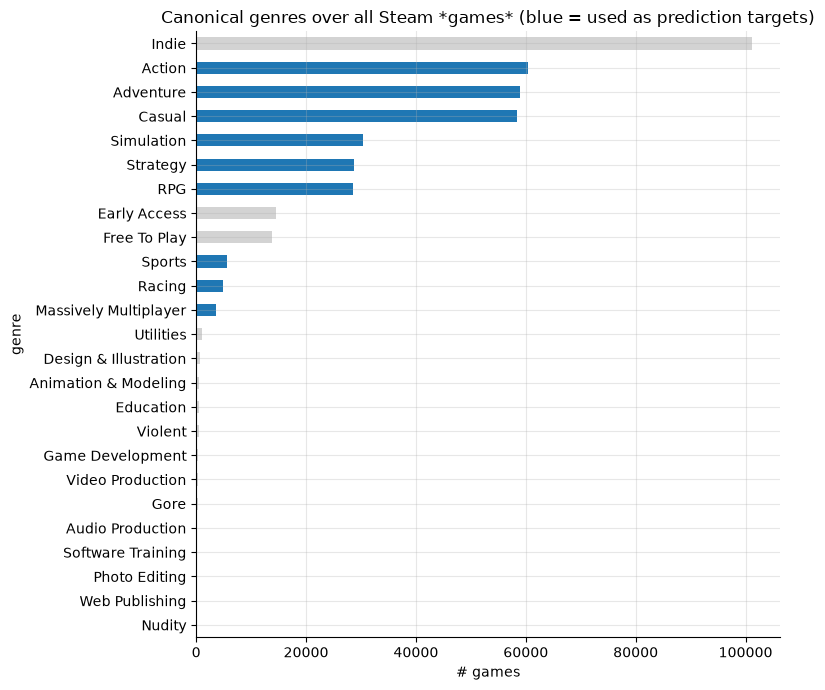

In [15]:
CANON = {
 # Action
 "Action":"Action","Acțiune":"Action","アクション":"Action","Azione":"Action","Aksiyon":"Action","Akcja":"Action",
 "Ação":"Action","动作":"Action","Acción":"Action","Экшены":"Action","Бойовики":"Action","Aksi":"Action",
 "動作":"Action","Actie":"Action","إثارة":"Action","Akció":"Action",
 # Adventure
 "Adventure":"Adventure","Aventură":"Adventure","Eventyr":"Adventure","Petualangan":"Adventure","Abenteuer":"Adventure",
 "Avventura":"Adventure","Пригоди":"Adventure","Macera":"Adventure","Aventure":"Adventure","Aventura":"Adventure",
 "Äventyr":"Adventure","冒險":"Adventure","アドベンチャー":"Adventure","Przygodowe":"Adventure",
 "Приключенческие игры":"Adventure","Dobrodružné":"Adventure","冒险":"Adventure",
 # Casual
 "Casual":"Casual","Basit Eğlence":"Casual","Kasual":"Casual","Rekreacyjne":"Casual","休閒":"Casual",
 "Неангажиращи":"Casual","カジュアル":"Casual","Gelegenheitsspiele":"Casual","Passatempo":"Casual","Fritid":"Casual",
 # Strategy
 "Strategy":"Strategy","Strategie":"Strategy","Stratégie":"Strategy","Estratégia":"Strategy","ストラテジー":"Strategy",
 "Stratégia":"Strategy","Strategické":"Strategy","策略":"Strategy","Strateji":"Strategy","Strategi":"Strategy",
 "Стратегии":"Strategy","Стратегії":"Strategy","Strategia":"Strategy","Estrategia":"Strategy",
 # Simulation
 "Simulation":"Simulation","Simulaatio":"Simulation","Simuladores":"Simulation","Szimuláció":"Simulation",
 "Simulação":"Simulation","Симулятори":"Simulation","Simulatoare":"Simulation","Симуляторы":"Simulation",
 "模拟":"Simulation","Simulatie":"Simulation","Simülasyon":"Simulation","Симулатори":"Simulation",
 "Simulering":"Simulation","Simulasi":"Simulation","Simulátory":"Simulation","Simuleringar":"Simulation",
 "Simulationen":"Simulation","Simulazione":"Simulation","Symulacje":"Simulation",
 # RPG
 "RPG":"RPG","Rollespill":"RPG","Rollenspiel":"RPG","Rol":"RPG","Рольові ігри":"RPG","RYO":"RPG",
 "Ролевые игры":"RPG","角色扮演":"RPG",
 # Sports
 "Sports":"Sports","Sport":"Sports","Esportes":"Sports","Spor":"Sports","体育":"Sports","Sportowe":"Sports",
 "Sportovní":"Sports","Deportes":"Sports","Спорт":"Sports",
 # Racing
 "Racing":"Racing","Гонки":"Racing","Corrida":"Racing","Corse":"Racing","Rennspiele":"Racing","Перегони":"Racing",
 "竞速":"Racing",
 # Massively Multiplayer
 "Massively Multiplayer":"Massively Multiplayer","Многопользовательские игры":"Massively Multiplayer",
 "MMO":"Massively Multiplayer","Multijogador Massivo":"Massively Multiplayer","Masivně multiplayerové":"Massively Multiplayer",
 "Devasa Çok Oyunculu":"Massively Multiplayer","Multigiocatore di massa":"Massively Multiplayer",
 "Multijugador masivo":"Massively Multiplayer",
 # Indie
 "Indie":"Indie","Nezávislé":"Indie","インディー":"Indie","Bağımsız Yapımcı":"Indie","獨立製作":"Indie","独立":"Indie",
 "Indépendant":"Indie","Інді":"Indie","Независими":"Indie","Niezależne":"Indie","Инди":"Indie",
 # Business-model / store labels
 "Free To Play":"Free To Play","Free to Play":"Free To Play","Бесплатные":"Free To Play","Gratis at spille":"Free To Play",
 "Gratuitos para Jogar":"Free To Play","免费开玩":"Free To Play","Gratis te spelen":"Free To Play",
 "Gratis att spela":"Free To Play","مجانية":"Free To Play",
 "Early Access":"Early Access","Acesso Antecipado":"Early Access",
 # Software / non-game & content descriptors
 "Bildung":"Education","Education":"Education","Spieleentwicklung":"Game Development","Game Development":"Game Development",
 "Web-Publishing":"Web Publishing","Web Publishing":"Web Publishing",
}
genres_raw["canonical"] = genres_raw["name"].map(CANON).fillna(genres_raw["name"])  # untranslated names are already English
print("distinct raw names:", genres_raw["name"].nunique(), "-> canonical genres:", genres_raw["canonical"].nunique())

app_genres = (app_genres_raw.merge(genres_raw[["id", "canonical"]], left_on="genre_id", right_on="id")
              [["appid", "canonical"]].rename(columns={"canonical": "genre"}).drop_duplicates())

PLAY_STYLE = ["Action", "Adventure", "Casual", "RPG", "Simulation", "Strategy", "Sports", "Racing", "Massively Multiplayer"]
GENRES = PLAY_STYLE + (["Indie"] if INCLUDE_INDIE else [])
K = len(GENRES)
print("Target genre vocabulary (K=%d):" % K, GENRES)

genre_counts_catalog = app_genres.merge(apps[["appid", "type"]], on="appid").query("type == 'game'")["genre"].value_counts()
ax = genre_counts_catalog.head(25)[::-1].plot.barh(figsize=(8, 7), color=["C0" if g in GENRES else "lightgray" for g in genre_counts_catalog.head(25).index[::-1]])
ax.set_title("Canonical genres over all Steam *games* (blue = used as prediction targets)"); ax.set_xlabel("# games"); plt.tight_layout(); plt.show()

**Choice of target vocabulary.** We keep the nine *play-style* genres. We drop:

* **store / business labels** — *Free To Play*, *Early Access* (they describe pricing or release status, not what the game is like);
* **Indie** — it is a production label attached to >50% of games; leaving it in would make "Indie" the trivially-correct answer for most users (set `INCLUDE_INDIE=True` to rerun with it);
* **software and content descriptors** — *Utilities*, *Design & Illustration*, *Violent*, *Gore*, …, which are not game genres.

We also restrict to apps with `type == 'game'` (no DLC, demos, soundtracks).

136,259 games with >=1 target genre; mean #target genres per game = 2.05


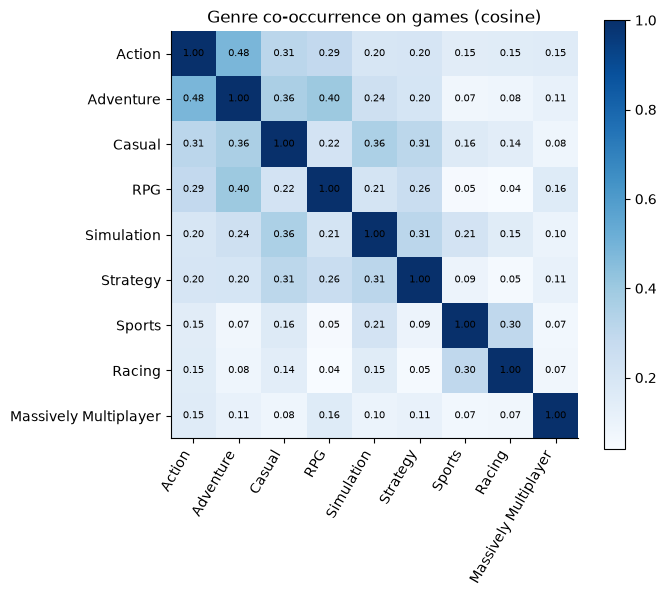

In [16]:
# ---- app x genre incidence matrix over games that have >=1 target genre ---------------
game_ids = set(apps.loc[apps["type"] == "game", "appid"])
ag = app_genres[app_genres["appid"].isin(game_ids) & app_genres["genre"].isin(GENRES)]
item_ids = np.sort(ag["appid"].unique())
item_index = pd.Series(np.arange(len(item_ids)), index=item_ids)
gidx = {g: k for k, g in enumerate(GENRES)}
A = sp.csr_matrix((np.ones(len(ag)), (item_index[ag["appid"]].values, ag["genre"].map(gidx).values)),
                  shape=(len(item_ids), K))
A.data[:] = 1.0
A_dense = A.toarray()
print(f"{len(item_ids):,} games with >=1 target genre; mean #target genres per game = {A_dense.sum(1).mean():.2f}")

co = A_dense.T @ A_dense
co_norm = co / np.sqrt(np.outer(np.diag(co), np.diag(co)))
fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(co_norm, cmap="Blues")
ax.set_xticks(range(K)); ax.set_xticklabels(GENRES, rotation=60, ha="right"); ax.set_yticks(range(K)); ax.set_yticklabels(GENRES)
for i in range(K):
    for j in range(K): ax.text(j, i, f"{co_norm[i,j]:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("Genre co-occurrence on games (cosine)"); ax.grid(False); plt.colorbar(im); plt.tight_layout(); plt.show()

### 2.3 Reviews — streaming load and column resolution

`reviews.csv` is ~640 MB, most of which is review text. We stream it in chunks and keep only the interaction columns. The helper below resolves column names defensively (the Steam API uses `author_steamid`, other exports use `steamid`).

In [17]:
header = pd.read_csv(DATA_DIR / "reviews.csv", nrows=0).columns.tolist()
print("reviews.csv columns:", header)

def pick(cands, required=True):
    for c in cands:
        if c in header: return c
    if required: raise KeyError(f"none of {cands} in reviews.csv")
    return None

C = {
    "user":     pick(["author_steamid", "steamid", "author.steamid", "user_id"]),
    "item":     pick(["appid", "app_id"]),
    "liked":    pick(["voted_up", "recommended"]),
    "time":     pick(["timestamp_created", "timestamp_updated", "created_at"]),
    "playtime": pick(["author_playtime_forever", "playtime_forever", "author_playtime_at_review", "playtime_at_review"], False),
    "n_owned":  pick(["author_num_games_owned", "num_games_owned"], False),
    "lang":     pick(["language"], False),
}
C = {k: v for k, v in C.items() if v is not None}
print("using:", C)

def to_bool(s):
    if s.dtype == bool: return s
    return s.astype(str).str.strip().str.lower().isin(["true", "1", "t", "yes"])

t0 = time.time(); parts = []
for chunk in pd.read_csv(DATA_DIR / "reviews.csv", usecols=list(C.values()), chunksize=REVIEW_CHUNK,
                         dtype={C["user"]: str}, low_memory=False):
    chunk = chunk.rename(columns={v: k for k, v in C.items()})
    chunk["liked"] = to_bool(chunk["liked"])
    t = chunk["time"]
    chunk["time"] = (pd.to_datetime(pd.to_numeric(t, errors="coerce"), unit="s", errors="coerce")
                     if pd.to_numeric(t, errors="coerce").notna().mean() > 0.9
                     else pd.to_datetime(t, errors="coerce", utc=True).dt.tz_localize(None))
    parts.append(chunk)
reviews_all = pd.concat(parts, ignore_index=True); del parts
print(f"loaded {len(reviews_all):,} reviews in {time.time()-t0:.1f}s; memory {reviews_all.memory_usage(deep=True).sum()/1e6:.0f} MB")
reviews_all.head()

reviews.csv columns: ['recommendationid', 'appid', 'author_steamid', 'author_num_games_owned', 'author_num_reviews', 'author_playtime_forever', 'author_playtime_last_two_weeks', 'author_playtime_at_review', 'author_last_played', 'language', 'review_text', 'timestamp_created', 'timestamp_updated', 'voted_up', 'votes_up', 'votes_funny', 'weighted_vote_score', 'comment_count', 'steam_purchase', 'received_for_free', 'written_during_early_access', 'created_at', 'updated_at']
using: {'user': 'author_steamid', 'item': 'appid', 'liked': 'voted_up', 'time': 'timestamp_created', 'playtime': 'author_playtime_forever', 'n_owned': 'author_num_games_owned', 'lang': 'language'}
loaded 1,048,148 reviews in 1.8s; memory 179 MB


,item,user,n_owned,playtime,lang,time,liked
0,264220,76561198085405844,760,12.0,polish,2014-05-02 19:46:05,True
1,1006440,76561198014439859,485,424.0,russian,2021-09-26 16:33:12,True
2,320721,76561198048038590,0,0.0,german,2021-09-26 17:00:31,False
3,1604700,76561197994386273,0,86.0,english,2021-09-26 17:00:48,True
4,1338560,76561198138996331,816,25.0,english,2021-09-26 17:03:39,True


,value
reviews,1048148
distinct users,701884
distinct apps,117311
positive rate,0.760933
missing user id,0.0
missing timestamp,0.0
"duplicate (user, app) pairs",8
first review,2010-10-19 10:04:22
last review,2025-09-06 14:37:00


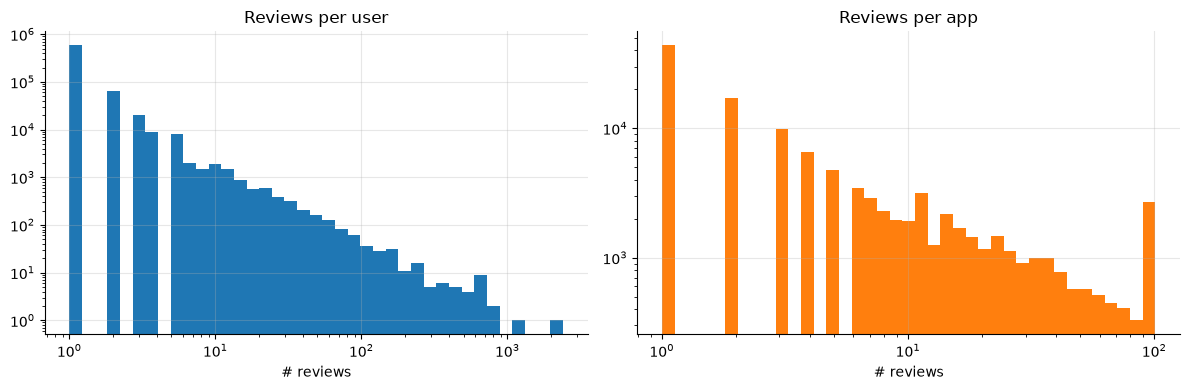

,count,mean,std,min,50%,75%,90%,99%,max
reviews per user,701884.0,1.493335,5.601685,1.0,1.0,1.0,2.0,8.0,2392.0


users with >=2 / >=3 / >=5 reviews: 111475 47337 18449


In [18]:
r = reviews_all
summary = pd.Series({
    "reviews": len(r),
    "distinct users": r["user"].nunique(),
    "distinct apps": r["item"].nunique(),
    "positive rate": r["liked"].mean(),
    "missing user id": r["user"].isna().mean(),
    "missing timestamp": r["time"].isna().mean(),
    "duplicate (user, app) pairs": r.duplicated(["user", "item"]).sum(),
    "first review": r["time"].min(), "last review": r["time"].max(),
})
display(summary.to_frame("value"))

per_user = r.groupby("user").size()
per_app = r.groupby("item").size()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(per_user, bins=np.logspace(0, np.log10(per_user.max() + 1), 40), color="C0")
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].set_title("Reviews per user"); axes[0].set_xlabel("# reviews")
axes[1].hist(per_app, bins=np.logspace(0, np.log10(per_app.max() + 1), 40), color="C1")
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_title("Reviews per app"); axes[1].set_xlabel("# reviews")
plt.tight_layout(); plt.show()
display(per_user.describe(percentiles=[.5, .75, .9, .99]).to_frame("reviews per user").T)
print("users with >=2 / >=3 / >=5 reviews:", *(int((per_user >= k).sum()) for k in (2, 3, 5)))

**Sparsity.** As in most review datasets, the per-user distribution is extremely long-tailed: most reviewers appear once or twice, and the reviews were crawled *per game*, so a user's footprint is only the subset of their reviews that landed on crawled games. This is the main challenge for the task — many users have very short histories, which is exactly where personalised models struggle and the global-mode baseline is hardest to beat. Users with too little history are kept as *background* data for fitting models but cannot be evaluated.

kept 830,740 / 830,740 reviews after cleaning (100.0%)


,share of games,share of reviews,positive rate
Action,0.444,0.467,0.754
Adventure,0.433,0.447,0.764
Casual,0.429,0.362,0.775
Simulation,0.223,0.262,0.725
RPG,0.209,0.231,0.744
Strategy,0.210,0.219,0.739
Sports,0.041,0.052,0.731
Racing,0.036,0.038,0.737
Massively Multiplayer,0.027,0.028,0.638


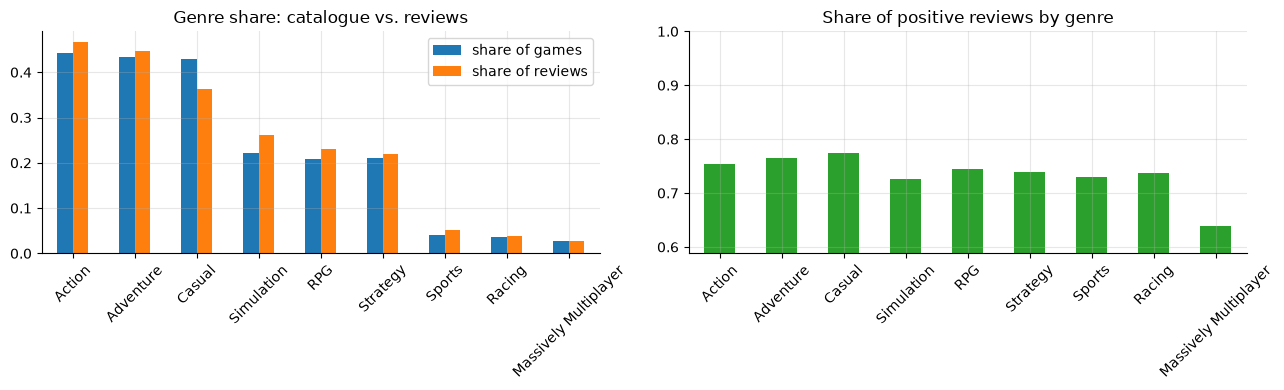

In [21]:
# ---- Clean: games only, target genres only, valid ids/times, one review per (user, game) ----------
n0 = len(r)
r = r.dropna(subset=["user", "item", "time"])
r = r[r["item"].isin(item_index.index)]
r = r.sort_values(["user", "time", "item"]).drop_duplicates(["user", "item"], keep="last")
r["iidx"] = item_index[r["item"]].values
if "playtime" in r: r["playtime"] = pd.to_numeric(r["playtime"], errors="coerce").fillna(0).clip(lower=0)
else: r["playtime"] = 0.0
print(f"kept {len(r):,} / {n0:,} reviews after cleaning ({len(r)/n0:.1%})")

# genre composition of reviews vs catalogue, and positivity by genre
G_rev = A_dense[r["iidx"].values]
share_rev = pd.Series(G_rev.sum(0) / len(r), GENRES)
share_cat = pd.Series(A_dense.sum(0) / len(A_dense), GENRES)
pos_rate = pd.Series((G_rev * r["liked"].values[:, None]).sum(0) / G_rev.sum(0), GENRES)
gdf = pd.DataFrame({"share of games": share_cat, "share of reviews": share_rev, "positive rate": pos_rate}).sort_values("share of reviews", ascending=False)
display(gdf.style.format("{:.3f}"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
gdf[["share of games", "share of reviews"]].plot.bar(ax=axes[0]); axes[0].set_title("Genre share: catalogue vs. reviews"); axes[0].tick_params(axis="x", rotation=45)
gdf["positive rate"].plot.bar(ax=axes[1], color="C2"); axes[1].set_ylim(gdf["positive rate"].min() - .05, 1); axes[1].set_title("Share of positive reviews by genre"); axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

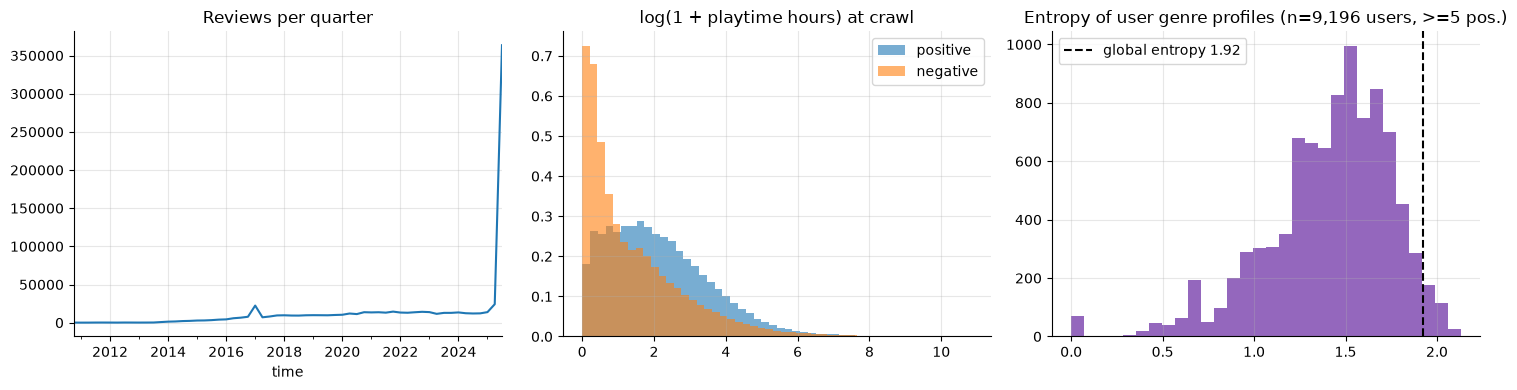

mean user entropy 1.41 vs global 1.92 -> users are more concentrated than the population, so personalisation has signal.


In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
try:    q = r.set_index("time").resample("QE")["liked"].size()   # pandas >= 2.2
except ValueError: q = r.set_index("time").resample("Q")["liked"].size()
q.plot(ax=axes[0]); axes[0].set_title("Reviews per quarter")
pt = np.log1p(r["playtime"] / 60)
axes[1].hist(pt[r["liked"]], bins=50, alpha=.6, label="positive", density=True)
axes[1].hist(pt[~r["liked"]], bins=50, alpha=.6, label="negative", density=True)
axes[1].set_title("log(1 + playtime hours) at crawl"); axes[1].legend()

# how concentrated are users' tastes? entropy of positive genre profile for users with >=5 positive reviews
pos = r[r["liked"]]
upos = pos.groupby("user").size(); heavy = upos[upos >= 5].index
Gh = pd.DataFrame(A_dense[pos.loc[pos["user"].isin(heavy), "iidx"].values], columns=GENRES)
Gh["user"] = pos.loc[pos["user"].isin(heavy), "user"].values
prof = Gh.groupby("user").sum(); prof = prof.div(prof.sum(1), axis=0)
ent = -(prof * np.log(prof.replace(0, np.nan))).sum(1)
glob = share_rev / share_rev.sum(); H_glob = -(glob * np.log(glob)).sum()
axes[2].hist(ent, bins=30, color="C4"); axes[2].axvline(H_glob, color="k", ls="--", label=f"global entropy {H_glob:.2f}")
axes[2].set_title(f"Entropy of user genre profiles (n={len(prof):,} users, >=5 pos.)"); axes[2].legend()
plt.tight_layout(); plt.show()
print(f"mean user entropy {ent.mean():.2f} vs global {H_glob:.2f} -> users are more concentrated than the population, so personalisation has signal.")

### 2.4 Pre-processing step 2 — temporal holdout split

For each user, reviews are sorted by time (position $p = 0,1,\dots$):

| role | definition |
|---|---|
| `test_target` | the user's **last positive** review |
| `val_target` | the last positive review **before** the test target |
| `val_hist` | all reviews (positive *and* negative) before the val target |
| `between` | negative reviews between val and test target (history for test only) |
| `future` | reviews after the test target → **dropped** |
| `background` | all reviews of users that are not eligible (fewer than `MIN_HISTORY` reviews before their val target); used only to fit collaborative models |

Two stages: **validation stage** (fit on `background ∪ val_hist`, predict `val_target`) for tuning and for training the supervised model, and **test stage** (fit on `background ∪ val_hist ∪ val_target ∪ between`, predict `test_target`).

In [23]:
r = r.reset_index(drop=True)
r["p"] = r.groupby("user").cumcount()
posr = r[r["liked"]]
test_p = posr.groupby("user")["p"].max()
posr2 = posr[posr["p"] < posr["user"].map(test_p)]
val_p = posr2.groupby("user")["p"].max()
eligible = val_p[val_p >= MIN_HISTORY].index

r["role"] = "background"
m = r["user"].isin(eligible)
tp, vp = r.loc[m, "user"].map(test_p), r.loc[m, "user"].map(val_p)
p = r.loc[m, "p"]
r.loc[m, "role"] = np.select([p == tp, p == vp, p < vp, (p > vp) & (p < tp)],
                             ["test_target", "val_target", "val_hist", "between"], "future")
r = r[r["role"] != "future"].reset_index(drop=True)

display(r["role"].value_counts().to_frame("rows"))
print(f"eligible (evaluated) users: {len(eligible):,}")
assert len(eligible) >= 500, "Too few users with repeat reviews for a per-user holdout - lower MIN_HISTORY or check the user id column."

users = np.array(sorted(eligible)); uindex = pd.Series(np.arange(len(users)), index=users)

,rows
role,
background,624863
val_hist,143129
val_target,26717
test_target,26717
between,4484


eligible (evaluated) users: 26,717


## 3. Modeling

### 3.1 Formulation
* **Input:** user $u$'s history $\mathcal H_u = [(i_1, y_1, t_1, \text{pt}_1), \dots]$ of reviewed games $i$, thumbs up/down $y$, time $t$ and playtime.
* **Output:** a score vector $s_u \in \mathbb R^K$ over the $K=9$ genres; recommendation $\hat g_u = \arg\max_g s_{u,g}$.
* **Objective:** rank a genre of the next positively-reviewed game first (maximise Hit@1); the supervised model optimises per-genre log-loss, a smooth surrogate.

Every model below is a function `fit(fit_df) -> scorer`, `scorer(hist_df) -> (n_users × K)` scores, so all models are evaluated through exactly the same pipeline.

### 3.2 Models

| # | Model | Idea (course link) | Cost |
|---|---|---|---|
| M0 | **Global mode / popularity** | most common genre among positive interactions | O(N) |
| M1 | **User mode** | argmax of the user's own positive genre counts, Laplace-smoothed toward popularity | O(N) |
| M2 | **Recency-weighted profile** | M1 with weights $\lambda^{\text{rank from most recent}}$; tastes drift (temporal dynamics) | O(N) |
| M3 | **Genre Markov chain** | $P(g_{next}\mid g_{prev})$ learned from consecutive positive reviews (sequential recommendation, FPMC-style first-order transition) | O(N + K²) |
| M4 | **Latent-factor model (truncated SVD)** | factorise the user×game matrix $R\approx U\Sigma V^\top$; project the user's history into latent space and back to genres: $s_u = R_u V V^\top A$ (collaborative filtering) | O(nnz·k) |
| M5 | **Logistic regression on features** | one-vs-rest LR, features = M1–M4 scores + negative-review profile + playtime-weighted profile + activity stats (supervised learning / feature engineering) | O(n·d·K) |

**Trade-offs.** M0 is free and robust but non-personalised. M1/M2 are interpretable and need no training but cannot say anything about users whose history is thin or who are about to branch out. M3 captures order ("after a Strategy game people often move to Simulation") but only conditions on the last item. M4 shares information across users (helps sparse users, captures that certain *games* co-occur beyond their genre labels) but requires choosing rank $k$, is sensitive to popularity bias, and the SVD of a large sparse matrix is the most expensive step. M5 can learn how to *combine* signals (e.g. trust the user profile more when the history is long), at the price of needing a held-out target to train on (we use the validation target — so no test leakage) and possible overfitting.

In [24]:
def hist_matrix(df, weight):
    # sparse (n_users x n_items) matrix of the given per-row weights, rows aligned with `users`
    df = df[df["user"].isin(users)]
    return sp.csr_matrix((weight.loc[df.index].values.astype(float), (uindex[df["user"]].values, df["iidx"].values)),
                         shape=(len(users), len(item_ids)))

def recency_rank(df, liked_only=True):
    # 0 for the most recent (liked) review in each user's history, 1 for the one before, ...
    d = df[df["liked"]] if liked_only else df
    return d.groupby("user")["p"].rank(ascending=False, method="first") - 1

def row_norm(M):
    s = M.sum(1, keepdims=True); return np.divide(M, s, out=np.zeros_like(M), where=s > 0)

# ---------------- M0: global mode / popularity -----------------------------------------
def fit_popularity(fit_df):
    pop = A_dense[fit_df.loc[fit_df["liked"], "iidx"].values].sum(0)
    pop = pop / pop.sum()
    return lambda hist: np.tile(pop, (len(users), 1)), pop

# ---------------- M1 / M2: (recency-weighted) user genre profile -------------------------
def fit_profile(fit_df, decay=1.0, alpha=0.5):
    _, pop = fit_popularity(fit_df)
    def score(hist):
        h = hist[hist["liked"]]
        w = decay ** recency_rank(hist)            # decay=1 -> plain counts (user mode)
        counts = (hist_matrix(h, w) @ A).toarray()
        return counts + alpha * pop                # smoothing: cold users fall back to popularity
    return score

# ---------------- M3: first-order genre Markov chain -----------------------------------
def fit_markov(fit_df, beta=1.0):
    _, pop = fit_popularity(fit_df)
    pos = fit_df[fit_df["liked"]].sort_values(["user", "p"])
    nxt = pos.groupby("user")["iidx"].shift(-1)
    pairs = pos.assign(nxt=nxt).dropna(subset=["nxt"])
    Gp = row_norm(A_dense[pairs["iidx"].values]); Gn = row_norm(A_dense[pairs["nxt"].astype(int).values])
    T = Gp.T @ Gn + beta * pop[None, :]           # K x K transition counts, smoothed
    T = row_norm(T)
    def score(hist):
        h = hist[hist["liked"]]
        last = h[recency_rank(hist) == 0]
        L = np.zeros((len(users), K))
        L[uindex[last["user"]].values] = row_norm(A_dense[last["iidx"].values])
        S = L @ T
        S[L.sum(1) == 0] = pop                    # no liked history -> popularity
        return S
    return score, T

# ---------------- M4: truncated-SVD latent factor model ---------------------------------
def fit_svd(fit_df, k=32):
    pos = fit_df[fit_df["liked"]]
    all_users = pos["user"].unique(); ui = pd.Series(np.arange(len(all_users)), index=all_users)
    R = sp.csr_matrix((np.ones(len(pos)), (ui[pos["user"]].values, pos["iidx"].values)), shape=(len(all_users), len(item_ids)))
    # down-weight very popular games (IDF-like) so the factors capture taste, not just popularity
    idf = np.log1p(R.shape[0] / (1 + np.asarray(R.sum(0)).ravel()))
    R = R @ sp.diags(idf)
    k = min(k, min(R.shape) - 1)
    _, s, Vt = svds(R.astype(np.float64), k=k)
    M = Vt.T @ (Vt @ (sp.diags(idf) @ A).toarray())          # items x K: latent-smoothed genre map
    def score(hist):
        h = hist[hist["liked"]]
        Rh = hist_matrix(h, pd.Series(1.0, index=h.index)) @ sp.diags(idf)
        return np.asarray(Rh @ M)
    return score

**Implementation notes.**
* All user-level scoring is vectorised with sparse matrices: a history becomes a sparse user×game matrix $H$, and genre profiles are just $H A$ where $A$ is the game×genre incidence matrix. This keeps every model at a few seconds even for ~1M reviews.
* **M4** exploits linearity: rather than scoring every (user, game) pair ($|U|\times|I|$ dense), we pre-compute $M = V(V^\top A)$ (games × genres) once and each user's genre scores are $H_u M$. Popular games are down-weighted with an IDF factor so the first singular vector does not just encode popularity.
* **Ties** (e.g. a user whose history has one Action/Adventure game) are broken by global popularity, added as a tiny $\epsilon$.

## 4. Evaluation

### 4.1 Metric implementation
Hit@1 is the natural metric for "recommend *one* genre": it is the probability the recommended genre is a genre of the game the user actually goes on to enjoy. Because games have ~2 target genres on average, a random guess already scores ≈ 2/9, and the mode baseline scores the *share of games tagged Action* — so we also report **macro-recall@1** (does the model ever recommend minority genres correctly?) and the **lift** over the baseline with confidence intervals. RMSE/accuracy on ratings would not fit: the output is a ranking over a small label set with multi-label ground truth, so ranking metrics (Hit@k, MRR) are the right family.

In [25]:
def targets(df, role):
    t = df[df["role"] == role]
    Y = np.zeros((len(users), K)); Y[uindex[t["user"]].values] = A_dense[t["iidx"].values]
    return Y

def rank_metrics(S, Y, pop):
    S = S + 1e-9 * pop[None, :]                   # deterministic tie-break by popularity
    order = np.argsort(-S, axis=1)
    rel = np.take_along_axis(Y, order, axis=1) > 0
    first = np.where(rel.any(1), rel.argmax(1), K)
    top1 = order[:, 0]
    hit1 = rel[:, 0]
    per_genre = np.array([hit1[(Y[:, g] > 0)][top1[Y[:, g] > 0] == g].size / max((Y[:, g] > 0).sum(), 1) for g in range(K)])
    return {"Hit@1": hit1.mean(), "Hit@3": rel[:, :3].any(1).mean(), "MRR": (1.0 / (first + 1)).mean(),
            "MacroRecall@1": per_genre.mean(), "#genres predicted": len(np.unique(top1)),
            "_hit1": hit1.astype(float), "_top1": top1, "_per_genre": per_genre}

stage = {
    "val":  dict(fit=r[r["role"].isin(["background", "val_hist"])],
                 hist=r[r["role"] == "val_hist"], Y=targets(r, "val_target")),
    "test": dict(fit=r[r["role"].isin(["background", "val_hist", "val_target", "between"])],
                 hist=r[r["role"].isin(["val_hist", "val_target", "between"])], Y=targets(r, "test_target")),
}
for s in stage.values(): s["pop"] = fit_popularity(s["fit"])[1]
print({k: (len(v["fit"]), len(v["hist"])) for k, v in stage.items()})

{'val': (767992, 143129), 'test': (799193, 174330)}


### 4.2 Hyper-parameter tuning on the validation target

svd k=8: 0.4691 (1.5s)
svd k=16: 0.4937 (2.0s)
svd k=32: 0.5054 (4.8s)
svd k=64: 0.5060 (13.1s)
user mode alpha=0.1 | recency decay=0.9, alpha=2.0 | markov beta=0.1 | svd k=64


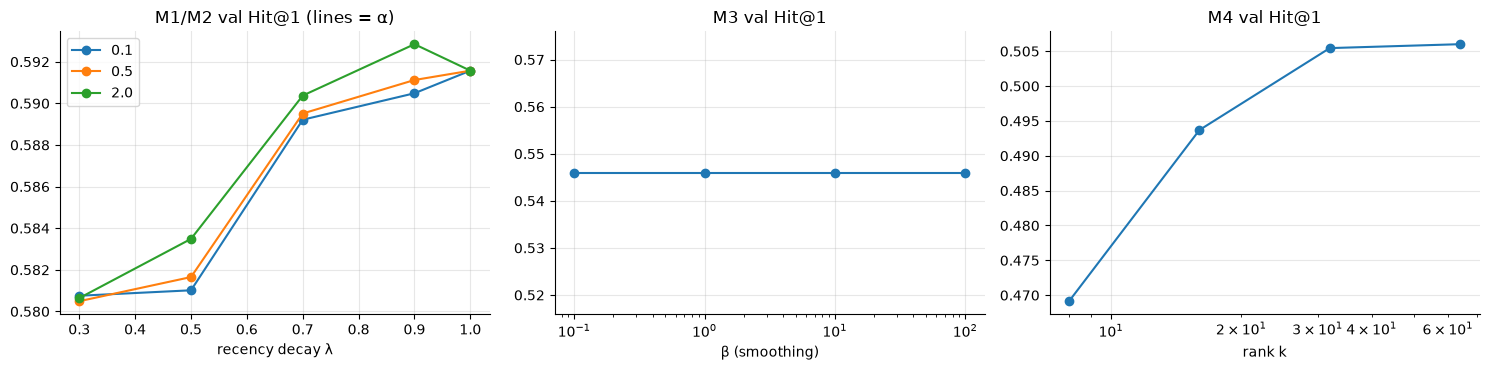

In [26]:
V = stage["val"]
def val_score(scorer): return rank_metrics(scorer(V["hist"]), V["Y"], V["pop"])["Hit@1"]

tune = {}
tune["profile"] = {(d, a): val_score(fit_profile(V["fit"], decay=d, alpha=a))
                   for d in [1.0, 0.9, 0.7, 0.5, 0.3] for a in [0.1, 0.5, 2.0]}
tune["markov"]  = {b: val_score(fit_markov(V["fit"], beta=b)[0]) for b in [0.1, 1.0, 10.0, 100.0]}
tune["svd"]     = {}
for k in [8, 16, 32, 64]:
    t0 = time.time(); tune["svd"][k] = val_score(fit_svd(V["fit"], k=k)); print(f"svd k={k}: {tune['svd'][k]:.4f} ({time.time()-t0:.1f}s)")

best_alpha_mode = max([a for (d, a) in tune["profile"] if d == 1.0], key=lambda a: tune["profile"][(1.0, a)])
best_decay, best_alpha = max(tune["profile"], key=tune["profile"].get)
best_beta = max(tune["markov"], key=tune["markov"].get)
best_k = max(tune["svd"], key=tune["svd"].get)
print(f"user mode alpha={best_alpha_mode} | recency decay={best_decay}, alpha={best_alpha} | markov beta={best_beta} | svd k={best_k}")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
tp = pd.Series(tune["profile"]).unstack(); tp.plot(marker="o", ax=axes[0]); axes[0].set_xlabel("recency decay λ"); axes[0].set_title("M1/M2 val Hit@1 (lines = α)")
pd.Series(tune["markov"]).plot(marker="o", logx=True, ax=axes[1]); axes[1].set_xlabel("β (smoothing)"); axes[1].set_title("M3 val Hit@1")
pd.Series(tune["svd"]).plot(marker="o", logx=True, ax=axes[2]); axes[2].set_xlabel("rank k"); axes[2].set_title("M4 val Hit@1")
plt.tight_layout(); plt.show()

### 4.3 M5 — supervised combiner (logistic regression)

Features for user $u$ (computed from the history *only*):

* normalised scores of M1 (counts), M2 (recency), M3 (Markov), M4 (SVD) — $4K$ features
* genre profile of **negative** reviews (what the user disliked) — $K$
* **playtime-weighted** positive profile, weights $\log(1+\text{minutes})$ — $K$
* activity: $\log(1+|\mathcal H_u|)$, fraction positive, log mean playtime — 3

Training labels: the genre set of the **validation target** (features from `val_hist`). One binary LR per genre (one-vs-rest, multi-label); genres are ranked by predicted probability. $C$ is selected by 5-fold CV over users *within* the validation stage, so the test target is never touched. At test time the same fitted model is applied to features from the test-stage history.

In [27]:
def make_features(st):
    fit, hist = st["fit"], st["hist"]
    blocks = {
        "mode":    row_norm(fit_profile(fit, 1.0, 0.0)(hist)),
        "recency": row_norm(fit_profile(fit, best_decay, 0.0)(hist)),
        "markov":  fit_markov(fit, best_beta)[0](hist),
        "svd":     fit_svd(fit, best_k)(hist),
    }
    blocks["svd"] = blocks["svd"] / (np.abs(blocks["svd"]).sum(1, keepdims=True) + 1e-12)
    neg = hist[~hist["liked"]]
    blocks["neg"] = row_norm((hist_matrix(neg, pd.Series(1.0, index=neg.index)) @ A).toarray())
    h = hist[hist["liked"]]
    blocks["playtime"] = row_norm((hist_matrix(h, np.log1p(h["playtime"]) + 0.1) @ A).toarray())
    g = hist.groupby("user").agg(n=("liked", "size"), pos=("liked", "mean"), pt=("playtime", "mean")).reindex(users).fillna(0)
    blocks["activity"] = np.c_[np.log1p(g["n"]), g["pos"], np.log1p(g["pt"])]
    names = [f"{b}:{gname}" for b in ["mode", "recency", "markov", "svd", "neg", "playtime"] for gname in GENRES] + ["log_n_hist", "frac_pos", "log_mean_playtime"]
    X = np.hstack([blocks[b] for b in ["mode", "recency", "markov", "svd", "neg", "playtime", "activity"]])
    return X, names

X_val, feat_names = make_features(stage["val"]); X_test, _ = make_features(stage["test"])
scaler = StandardScaler().fit(X_val); Xv, Xt = scaler.transform(X_val), scaler.transform(X_test)
Yv = (stage["val"]["Y"] > 0).astype(int)
print("feature matrix:", Xv.shape)

def fit_lr(X, Y, C):
    return [LogisticRegression(C=C, max_iter=500).fit(X, Y[:, g]) if 0 < Y[:, g].sum() < len(Y) else None for g in range(K)]
def predict_lr(models, X, pop):
    return np.column_stack([m.predict_proba(X)[:, 1] if m is not None else np.full(len(X), pop[g]) for g, m in enumerate(models)])

folds = RNG.integers(0, 5, len(users)); cv = {}
for Cc in [0.01, 0.1, 1.0, 10.0]:
    hits = []
    for f in range(5):
        tr, te = folds != f, folds == f
        S = predict_lr(fit_lr(Xv[tr], Yv[tr], Cc), Xv[te], stage["val"]["pop"])
        hits.append(rank_metrics(S, Yv[te], stage["val"]["pop"])["Hit@1"])
    cv[Cc] = np.mean(hits)
best_C = max(cv, key=cv.get); print("CV Hit@1 by C:", {k: round(v, 4) for k, v in cv.items()}, "-> C =", best_C)
lr_models = fit_lr(Xv, Yv, best_C)

coef = pd.DataFrame([m.coef_[0] if m is not None else np.zeros(len(feat_names)) for m in lr_models], index=GENRES, columns=feat_names)
# for each genre, weight on *its own* score from each block: how much does the LR trust each signal?
own = pd.DataFrame({b: [coef.loc[g, f"{b}:{g}"] for g in GENRES] for b in ["mode", "recency", "markov", "svd", "neg", "playtime"]}, index=GENRES)
display(own.style.background_gradient(cmap="RdBu_r", axis=None).format("{:.2f}").set_caption("LR weight on each genre's own feature (standardised)"))

feature matrix: (26717, 57)
CV Hit@1 by C: {0.01: np.float64(0.5982), 0.1: np.float64(0.5983), 1.0: np.float64(0.5992), 10.0: np.float64(0.5991)} -> C = 1.0


,mode,recency,markov,svd,neg,playtime
Action,-0.08,0.33,0.07,0.23,0.20,0.03
Adventure,-0.67,0.58,0.13,0.17,0.14,0.26
Casual,-0.38,0.57,0.06,0.18,0.10,0.18
RPG,-0.26,0.32,0.14,0.29,0.17,0.24
Simulation,-1.09,0.95,0.02,0.18,0.13,0.42
Strategy,-0.13,0.37,-0.01,0.18,0.18,0.16
Sports,-0.27,0.74,0.18,0.36,0.10,-0.34
Racing,-0.73,0.17,0.17,0.14,0.09,0.65
Massively Multiplayer,-0.11,-0.05,0.30,0.25,0.12,0.24


### 4.4 Test-set results
All models are now refit on the test-stage data with the tuned hyper-parameters and evaluated once on the held-out **test target**.

In [28]:
T = stage["test"]
pop_scorer, pop_test = fit_popularity(T["fit"])
scores = {
    "M0 Global mode (baseline)": pop_scorer(T["hist"]),
    "M1 User mode":              fit_profile(T["fit"], 1.0, best_alpha_mode)(T["hist"]),
    "M2 Recency-weighted":       fit_profile(T["fit"], best_decay, best_alpha)(T["hist"]),
    "M3 Genre Markov chain":     fit_markov(T["fit"], best_beta)[0](T["hist"]),
    "M4 Latent factors (SVD)":   fit_svd(T["fit"], best_k)(T["hist"]),
    "M5 Logistic regression":    predict_lr(lr_models, Xt, pop_test),
}
# reference point: uniformly random genre ranking (expected value)
rand = {"Hit@1": (T["Y"].sum(1) / K).mean()}

res = {name: rank_metrics(S, T["Y"], pop_test) for name, S in scores.items()}
table = pd.DataFrame({n: {k: v for k, v in m.items() if not k.startswith("_")} for n, m in res.items()}).T
base = table.loc["M0 Global mode (baseline)", "Hit@1"]
table["Δ Hit@1 vs mode"] = table["Hit@1"] - base

# bootstrap CIs (resample users) + paired test vs. the baseline
H = np.column_stack([res[n]["_hit1"] for n in scores]); n = len(H)
boot = np.array([H[RNG.integers(0, n, n)].mean(0) for _ in range(N_BOOT)])
lo, hi = np.percentile(boot, [2.5, 97.5], axis=0)
diff = boot - boot[:, [0]]
table["Hit@1 95% CI"] = [f"[{a:.3f}, {b:.3f}]" for a, b in zip(lo, hi)]
table["p (≤ mode)"] = (diff <= 0).mean(0); table.iloc[0, table.columns.get_loc("p (≤ mode)")] = np.nan
print(f"evaluated users: {n:,} | random-ranking expected Hit@1: {rand['Hit@1']:.3f}")
display(table.style.format({"Hit@1": "{:.3f}", "Hit@3": "{:.3f}", "MRR": "{:.3f}", "MacroRecall@1": "{:.3f}",
                            "Δ Hit@1 vs mode": "{:+.3f}", "p (≤ mode)": "{:.3f}"}).highlight_max(subset=["Hit@1", "Hit@3", "MRR", "MacroRecall@1"], color="#cde"))

evaluated users: 26,717 | random-ranking expected Hit@1: 0.226


,Hit@1,Hit@3,MRR,MacroRecall@1,#genres predicted,Δ Hit@1 vs mode,Hit@1 95% CI,p (≤ mode)
M0 Global mode (baseline),0.439,0.874,0.654,0.111,1.000000,+0.000,"[0.432, 0.444]",nan
M1 User mode,0.614,0.903,0.763,0.180,9.000000,+0.175,"[0.608, 0.619]",0.000
M2 Recency-weighted,0.616,0.903,0.764,0.182,9.000000,+0.177,"[0.609, 0.621]",0.000
M3 Genre Markov chain,0.555,0.882,0.727,0.146,3.000000,+0.117,"[0.549, 0.561]",0.000
M4 Latent factors (SVD),0.511,0.873,0.700,0.139,9.000000,+0.072,"[0.504, 0.516]",0.000
M5 Logistic regression,0.613,0.907,0.764,0.174,8.000000,+0.174,"[0.607, 0.618]",0.000


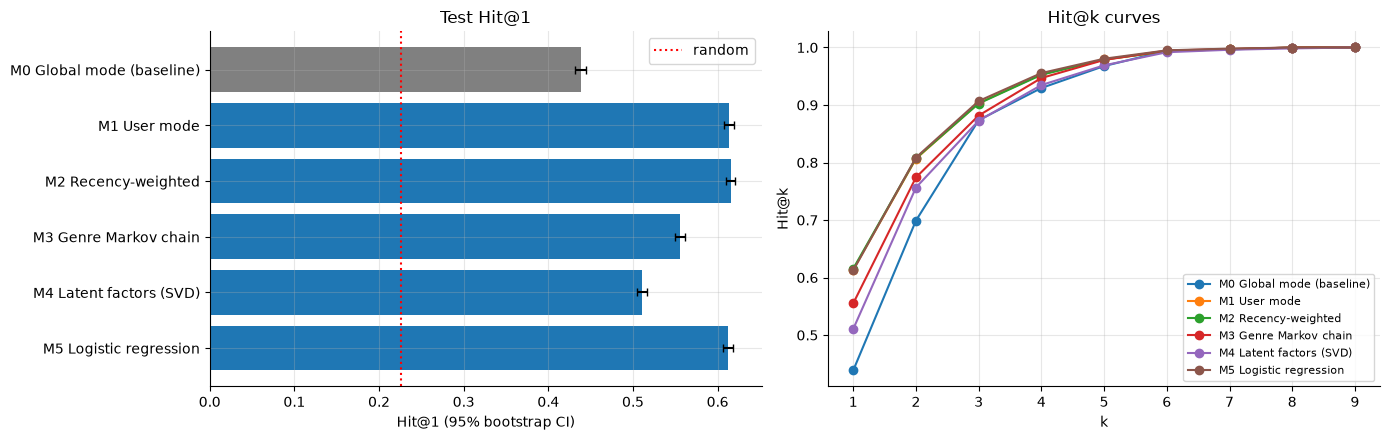

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
names = list(scores); y = np.arange(len(names))
axes[0].barh(y, table["Hit@1"], xerr=[table["Hit@1"] - lo, hi - table["Hit@1"]], color=["gray"] + ["C0"] * (len(names) - 1), capsize=3)
axes[0].axvline(rand["Hit@1"], color="r", ls=":", label="random")
axes[0].set_yticks(y); axes[0].set_yticklabels(names); axes[0].invert_yaxis(); axes[0].set_xlabel("Hit@1 (95% bootstrap CI)"); axes[0].legend()
axes[0].set_title("Test Hit@1")
for name, m in res.items():
    S = scores[name] + 1e-9 * pop_test; order = np.argsort(-S, 1); rel = np.take_along_axis(T["Y"], order, 1) > 0
    axes[1].plot(range(1, K + 1), [rel[:, :k].any(1).mean() for k in range(1, K + 1)], marker="o", label=name)
axes[1].set_xlabel("k"); axes[1].set_ylabel("Hit@k"); axes[1].set_title("Hit@k curves"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 4.5 Validity checks

1. **Does the gain depend on how much we know about the user?** Personalised models should improve as history grows; the baseline should be flat.
2. **Per-genre recall** — the mode baseline only ever recommends one genre. A useful recommender should correctly recommend minority genres (RPG, Strategy, Racing…) for the users who like them.
3. **Prediction distribution** — compare how often each genre is recommended against how often it is actually a target.

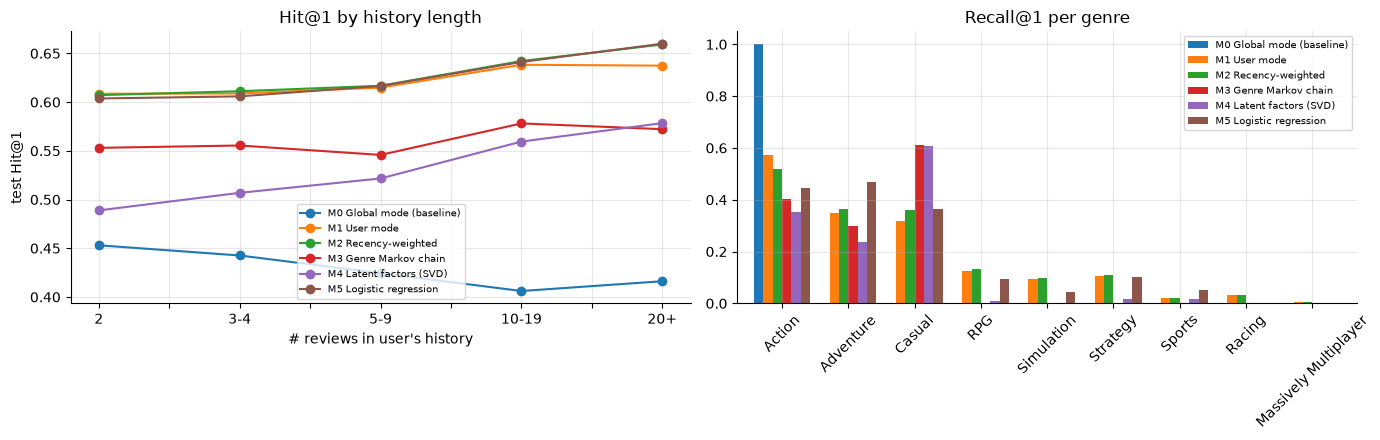

,M0 Global mode (baseline),M1 User mode,M2 Recency-weighted,M3 Genre Markov chain,M4 Latent factors (SVD),M5 Logistic regression,#users
2,0.453,0.609,0.607,0.553,0.489,0.604,9889
3-4,0.443,0.609,0.611,0.555,0.507,0.606,8150
5-9,0.424,0.615,0.617,0.546,0.522,0.617,5297
10-19,0.406,0.638,0.642,0.578,0.559,0.641,2093
20+,0.416,0.637,0.659,0.572,0.578,0.660,1288


,actual target share,recommended by M2 Recency-weighted,recommended by M0
Action,0.216,0.359,1.000
Adventure,0.237,0.274,0.000
Casual,0.190,0.234,0.000
RPG,0.109,0.047,0.000
Simulation,0.114,0.043,0.000
Strategy,0.094,0.038,0.000
Sports,0.020,0.002,0.000
Racing,0.015,0.003,0.000
Massively Multiplayer,0.005,0.000,0.000


In [30]:
n_hist = T["hist"].groupby("user").size().reindex(users).fillna(0).values
bins = pd.cut(n_hist, [0, 1, 2, 4, 9, 19, np.inf], labels=["1", "2", "3-4", "5-9", "10-19", "20+"])
by_len = pd.DataFrame({name: pd.Series(res[name]["_hit1"]).groupby(bins.codes).mean().values for name in scores},
                      index=bins.categories[np.unique(bins.codes[bins.codes >= 0])])
by_len["#users"] = pd.Series(bins).value_counts().reindex(by_len.index).values

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
by_len.drop(columns="#users").plot(marker="o", ax=axes[0]); axes[0].set_xlabel("# reviews in user's history"); axes[0].set_ylabel("test Hit@1")
axes[0].set_title("Hit@1 by history length"); axes[0].legend(fontsize=7)
pg = pd.DataFrame({n: res[n]["_per_genre"] for n in scores}, index=GENRES)
pg.plot.bar(ax=axes[1], width=.85); axes[1].set_title("Recall@1 per genre"); axes[1].tick_params(axis="x", rotation=45); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()
display(by_len.style.format("{:.3f}", subset=list(scores)))

best_name = table["Hit@1"].idxmax()
dist = pd.DataFrame({"actual target share": T["Y"].sum(0) / T["Y"].sum(),
                     f"recommended by {best_name}": np.bincount(res[best_name]["_top1"], minlength=K) / n,
                     "recommended by M0": np.bincount(res["M0 Global mode (baseline)"]["_top1"], minlength=K) / n}, index=GENRES)
display(dist.style.format("{:.3f}"))

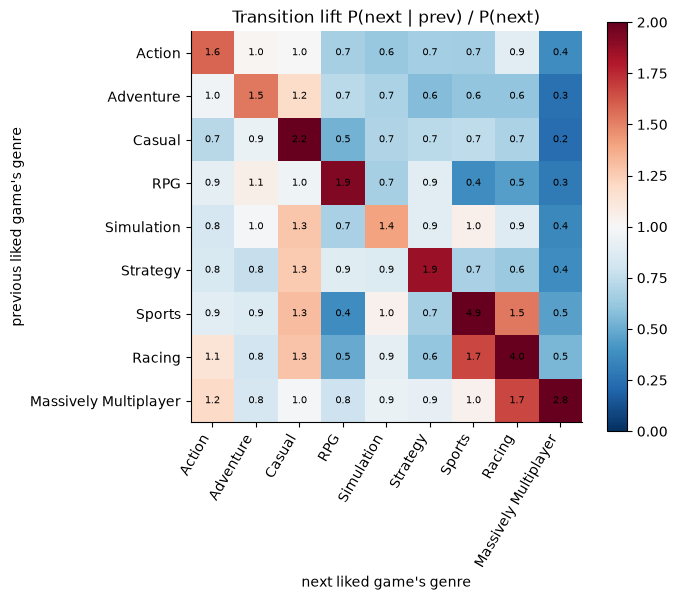

In [31]:
# Markov transition matrix learnt on the test-stage data: what genre tends to follow what?
_, Tm = fit_markov(T["fit"], best_beta)
lift = Tm / pop_test[None, :]
fig, ax = plt.subplots(figsize=(7, 6)); im = ax.imshow(lift, cmap="RdBu_r", vmin=0, vmax=2)
ax.set_xticks(range(K)); ax.set_xticklabels(GENRES, rotation=60, ha="right"); ax.set_yticks(range(K)); ax.set_yticklabels(GENRES)
ax.set_xlabel("next liked game's genre"); ax.set_ylabel("previous liked game's genre"); ax.grid(False)
for i in range(K):
    for j in range(K): ax.text(j, i, f"{lift[i,j]:.1f}", ha="center", va="center", fontsize=7)
ax.set_title("Transition lift P(next | prev) / P(next)"); plt.colorbar(im); plt.tight_layout(); plt.show()

## 5. Final recommendations for every user

The best model on the held-out test target is refit on **all** available history (including the test target) and used to recommend a genre to every user — including users who were too sparse to evaluate (they receive their history-based or, if they have none, the popularity recommendation).

In [32]:
all_users = np.array(sorted(r["user"].unique()))
full = r.copy()
# reuse the scorers with a user index covering everyone
users_eval, uindex_eval = users, uindex
users, uindex = all_users, pd.Series(np.arange(len(all_users)), index=all_users)
pop_full = fit_popularity(full)[1]
full_scorers = {
    "M0 Global mode (baseline)": lambda: np.tile(pop_full, (len(users), 1)),
    "M1 User mode":              lambda: fit_profile(full, 1.0, best_alpha_mode)(full),
    "M2 Recency-weighted":       lambda: fit_profile(full, best_decay, best_alpha)(full),
    "M3 Genre Markov chain":     lambda: fit_markov(full, best_beta)[0](full),
    "M4 Latent factors (SVD)":   lambda: fit_svd(full, best_k)(full),
    "M5 Logistic regression":    lambda: predict_lr(lr_models, scaler.transform(make_features(dict(fit=full, hist=full))[0]), pop_full),
}
S_full = full_scorers[best_name]()
order = np.argsort(-(S_full + 1e-9 * pop_full), 1)
recs = pd.DataFrame({"user": all_users,
                     "recommended_genre": np.array(GENRES)[order[:, 0]],
                     "2nd": np.array(GENRES)[order[:, 1]], "3rd": np.array(GENRES)[order[:, 2]],
                     "n_reviews": full.groupby("user").size().reindex(all_users).values})
users, uindex = users_eval, uindex_eval
print(f"model used: {best_name} | users: {len(recs):,}")
display(recs.sample(10, random_state=0))
display(recs["recommended_genre"].value_counts(normalize=True).to_frame("share of users"))
recs.to_csv("genre_recommendations.csv", index=False)

model used: M2 Recency-weighted | users: 580,086


,user,recommended_genre,2nd,3rd,n_reviews
319743,76561198296181671,Action,Adventure,Casual,1
498420,76561199211853677,Simulation,Strategy,Action,1
54760,76561198005018895,Action,Adventure,Casual,2
336322,76561198328267960,Action,Adventure,Casual,2
59340,76561198007432618,Simulation,Strategy,Action,1
51380,76561198002808076,Casual,Action,Adventure,1
113388,76561198041301290,Simulation,Strategy,Action,1
275337,76561198194611114,Action,Adventure,RPG,1
182873,76561198084708211,Action,Strategy,Adventure,1
547169,76561199595796473,Action,Adventure,Casual,1


,share of users
recommended_genre,
Action,0.577432
Adventure,0.173771
Casual,0.118641
Simulation,0.063546
RPG,0.033223
Strategy,0.027243
Racing,0.002977
Sports,0.002917
Massively Multiplayer,0.000252


## 6. Discussion

**What the results show.** *(Fill in after running — the cells above print every number referenced here.)* Compare each model's Hit@1 and CI against the global-mode row: a positive Δ with `p (≤ mode)` < 0.05 means the model reliably beats the baseline. The history-length plot shows *where* personalisation helps: with one prior review the user-mode and Markov models are essentially guessing that review's genres again, whereas with longer histories the recency profile and LR combiner pull ahead. Macro-recall@1 shows the baseline's blind spot: it never recommends RPG, Strategy, Racing, etc., even to users who play little else.

**Advantages / disadvantages in practice.**
* *Global mode* — zero cost, no cold-start problem, but identical for everyone; its Hit@1 equals the share of liked games tagged with that genre, which is high only because genres are multi-label and one genre dominates.
* *User / recency profiles* — strong, transparent baselines; recency helps when tastes drift; fail for cold users (fallback to popularity via α).
* *Markov chain* — captures sequential patterns (diagonal lift > 1 shows people stay within a genre; off-diagonal cells show common transitions) but forgets everything except the last game.
* *SVD latent factors* — share information across users so a single liked game informs related genres; quality depends on rank k and on how many repeat users the crawl contains (the dataset is crawled per game, so the user×game matrix is very sparse).
* *Logistic regression combiner* — learns per-genre how much to trust each signal; most accurate when trained on enough users, but adds a training stage and depends on the validation target.

**Limitations / threats to validity.** Reviews are only a sample of what users play (people review a small fraction of their library), and the crawl is per-game, so user histories are truncated. Genres are store-assigned and coarse. The background users and the item-side statistics are pooled over all time (mild global-time leakage across users, standard in leave-last-out protocols); per-user ordering is strictly respected.

**Related work.** Steam recommendation was studied in the course's own datasets (Kang & McAuley, *Self-Attentive Sequential Recommendation*, 2018; Pathak, Gupta & McAuley, *Generating and Personalizing Bundle Recommendations on Steam*, SIGIR 2017; Wan & McAuley, *Item recommendation on monotonic behavior chains*, RecSys 2018). Our M3 is the first-order Markov component of FPMC (Rendle et al., 2010); M4 follows the latent-factor family (Koren, Bell & Volinsky, 2009), with SVD as a non-iterative alternative to ALS/BPR. Natural extensions: BPR-MF or SASRec at the game level aggregated to genres, and text features from the review body (TF-IDF → genre) for users with few reviews.